Simple models with small datasets can often be fit in a single step, while larger datasets and more complex models must be fit by repeatedly using the model with training data and comparing the output with the expected label. If the prediciton is accurate enough, we consider the model trained. If not, we adjust the model slightly and loop again. 

**Hyperparameters** are values that change the way that the model is fit during these loops. Learning rate, for example, is a hyperparameter that sets how much a model is adjusted during each training cycle. A high learning rate means a model can be trained faster, but if its too high, the adjustment can be so large that the model never "finely tuned" and not optimal.

**Preprocessing** refers to changes you make to your data before its passed to the model. Preprocessing can involve cleaning your dataset but it can also include changing the format of your data so its easier for the model to use. 

**Scaling features** is scaling features between zero and one. For example, the weight of a bike and the distance a person travels on a bike may be two different numbers, but by scaling both numbers to between zero and one allows models to learn more effectively from the data.

In ML, we can also **use categories as features**. These features are represented by 0 or 1 values in one-hot vectors; vectors that have a 0 or 1 for each possible value.

In [11]:
# import modules we will need for this notebook
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# load training dataset
bike_data = pd.read_csv('daily-bike-share.csv')
bike_data['day'] = pd.DatetimeIndex(bike_data['dteday']).day
numeric_features = ['temp', 'atemp', 'hum', 'windspeed']
categorical_features = ['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'day']

bike_data[numeric_features + ['rentals']].describe()
print(bike_data.head())

# Seperate features and labels
# After separating the dataset, we now have numpy arrays named X containing the features and y containing the labels.
X, y = bike_data[['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit','temp', 'atemp', 'hum', 'windspeed']].values, bike_data['rentals'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)

print(f'Training Set: { X_train.shape[0]} samples\nTest Set: {X_test.shape[0]} samples')

   instant    dteday  season  yr  ...       hum  windspeed  rentals  day
0        1  1/1/2011       1   0  ...  0.805833   0.160446      331    1
1        2  1/2/2011       1   0  ...  0.696087   0.248539      131    2
2        3  1/3/2011       1   0  ...  0.437273   0.248309      120    3
3        4  1/4/2011       1   0  ...  0.590435   0.160296      108    4
4        5  1/5/2011       1   0  ...  0.436957   0.186900       82    5

[5 rows x 15 columns]
Training Set: 511 samples
Test Set: 220 samples


GradientBoostingRegressor()
Mean Squared Error: 104277.66
Root Mean Squared Error: 322.92
R^2 Score: 0.80


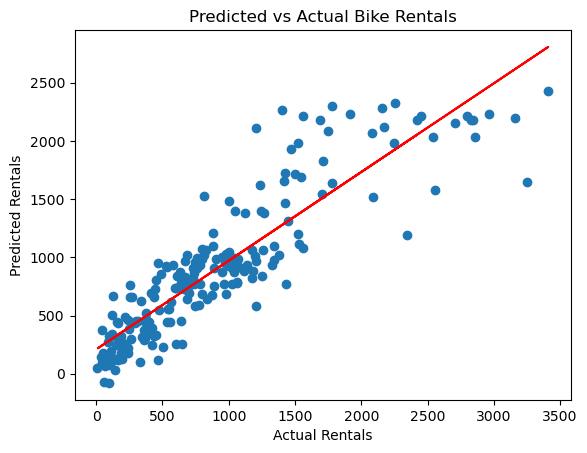

In [12]:
# Train the model

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Fit a lasso model on the training set
model = GradientBoostingRegressor().fit(X_train, y_train)
print(model)

# Evaluate the Trained model
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2 = r2_score(y_test, predictions)
print(f'R^2 Score: {r2:.2f}')

# Plot predicted vs actual values
plt.scatter(y_test, predictions)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Predicted vs Actual Bike Rentals')
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test,p(y_test),color='red')
plt.show()
